# PHÂN LOẠI CẢM XÚC ĐÁNH GIÁ ĐIỆN MÁY XANH
**3 nhóm cảm xúc: Tiêu cực (-1), Trung tính (0), Tích cực (1).**

**Quy trình thực hiện (Pipeline)**:
1. **Data explore**: Khám phá dữ liệu, đánh giá độ tin cậy giữa nhãn Người và AI
2. **Split**: Phân tách tập Train / Validation / Test
3. **Preprocessed**: Tiền xử lý chữ thường, teencode, tách từ và lọc từ dừng
4. **Feature extraction**: Trích chọn đặc trưng văn bản (BoW, TF-IDF, Word2Vec)
5. **Modeling**: Huấn luyện các mô hình phân loại (Naive Bayes, SVM)
6. **Evaluation**: Đánh giá hiệu năng và phân tích lỗi


In [1]:
from pathlib import Path
import re
import unicodedata
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gensim.models import Word2Vec
from underthesea import word_tokenize
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, f1_score, cohen_kappa_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

pd.set_option('display.max_colwidth', 120)
data, OUT = Path('data'), Path('out')
OUT.mkdir(exist_ok=True)
SEED = 42
LABELS = [-1, 0, 1]
NAMES = ['Tiêu cực', 'Trung tính', 'Tích cực']

## 1. Data explore (Khám phá dữ liệu)
data/
- `04.human_labels.xlsx`  : thủ công 500 mẫu làm test 
- `ai_label1.xlsx`        : tự động 500 mẫu để so sánh
- `05.claude_v2.csv`      : Gán toàn bộ mẫu 
- `teencode.csv` & `tu_dung.txt`: Chuẩn hoá viết tắt và stopword


,review_id,noi_dung,label
0,49971282,"Tủ lạnh mua về được 3 ngày thì bắt đầu réo, kêu to. Gọi bảo hành thì chuyển hãng, hãng về xem báo tủ lạnh hoạt động ...",-1
1,58627519,"Nồi này rất dở, mua về hàng Nhật ba bữa là hư phải mang đi hảo hành sử dụng tháng là bóng lớp chống dính cái nắp thi...",-1
2,30815134,"Nồi cơm quá tệ so với thương hiệu đang mang tên.Tôi mua cái này vs giá 650k tại ĐMX tháng 6.2018,mới mha về nấu cơm ...",-1
3,56917103,Cục nóng ồn quá,-1
4,49287524,"Mình mua nồi chưa được 1 năm nhưng nấu cơm không chín, giữa chừng cứ bị bật nút lên, rất bất tiện. Mong được DMX hỗ trợ",-1


- Số mẫu người gán tay: 500 câu
- Số mẫu AI gán thử   : 500 câu
- Toàn bộ tập dữ liệu : 5493 câu
--> Độ khớp : 97.40% | Kappa: 0.9565


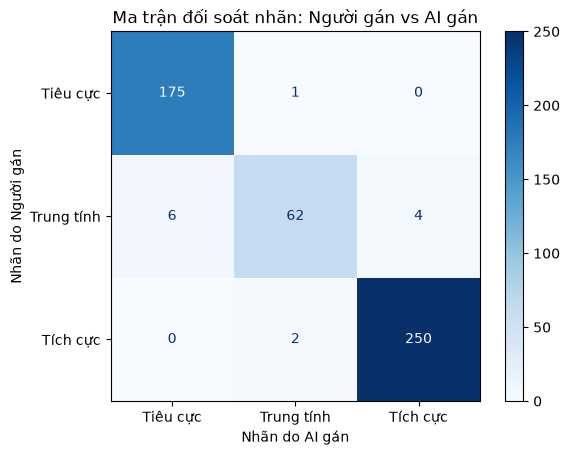

In [2]:
df_per = pd.read_excel(data / "04.human_labels.xlsx")
df_ai = pd.read_excel(data / "ai_label1.xlsx")
df_tong = pd.read_csv(data / "05.claude_v2.csv")
df_clean = pd.read_csv(data / "02.clean_reviews.csv")

display(df_per.head())

print(f"- Số mẫu người gán tay: {len(df_per)} câu")
print(f"- Số mẫu AI gán thử   : {len(df_ai)} câu")
print(f"- Toàn bộ tập dữ liệu : {len(df_tong)} câu")

y_per = df_per['label'].astype(int)
y_ai = df_ai['label'].astype(int)

do_khop = accuracy_score(y_per, y_ai)
kappa = cohen_kappa_score(y_per, y_ai)
print(f"--> Độ khớp : {do_khop:.2%} | Kappa: {kappa:.4f}")

# Vẽ ma trận nhầm lẫn đối soát nhãn
cm_doi_soat = confusion_matrix(y_per, y_ai, labels=LABELS)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_doi_soat, display_labels=NAMES)
disp.plot(cmap='Blues')
plt.title("Ma trận đối soát nhãn: Người gán vs AI gán")
plt.xlabel("Nhãn do AI gán")
plt.ylabel("Nhãn do Người gán")
plt.show()


### Các câu AI gán khác người (Độ lệch nhãn mẫu kiểm thử)


In [3]:
# So sánh chi tiết các mẫu có sự bất đồng giữa nhãn người chấm và Claude AI
lech = pd.DataFrame({
    'noi_dung': df_per.set_index('review_id')['noi_dung'],
    'nguoi': y_per.values,
    'ai': y_ai.values
}).query('nguoi != ai')
print(f'{len(lech)}/{len(y_per)} câu AI gán khác người')
display(lech)


13/500 câu AI gán khác người


,noi_dung,nguoi,ai
review_id,,,
57241275,Máy lúc mới lắp thì chạy OK sau hơn 1 tháng sử dụng thì máy làm mát rất yếu gọi nhân viên xuống kiểm tra thì lại báo...,0,-1
56752347,"Sau 1 tuần sd thì thấycánh quạt khi đóng hở cả khúc côn trùng dễ vào, cánh cũng ko hạ sâu chỉ lơ lớ, dàn lạnh lâu lâ...",0,-1
58871869,"Tai nghe bên phải sử dụng chưa đc 2p thì hết pin mặc dù đã sạc 100%, còn bên trái đang có dấu hiệu tụt pin rất nhanh",0,-1
52800748,"Mẫu mã đẹp, về chất lượng thì khi nấu cần ấn nút 2 lần cơm mới chín",1,0
58025248,Điều khó chịu nhất là KHÔNG CÓ NHỚ VỊ TRÍ ĐÃ ĐI VÀ KHÔNG VẼ BẢN ĐỒ. Với tầm giá này thì đáng ra phải làm tốt hơn con...,1,0
56947827,Sao nút swing đảo gió lên xuống thì thấy có hoạt động còn nuta direct điều chỉnh hướng gió qua lại thì nhân vô nó ko...,0,-1
52212361,"Tạm thời thấy ko vấn đề gì, nv tư vấn nhiệt tình",0,1
46374685,Cho mình hỏi sao tủ của mình nóng vậy Chuyển tới mình để tới 3 tiếng mới ngăm điện ạ,-1,0
34038831,Em nói thật chứ mấy bác nên đọc kĩ hướng dẫn rồi hẵng sử dung Máy ngon trong tầm giá mát nói chung chỉ thế thôi.kaka,0,1


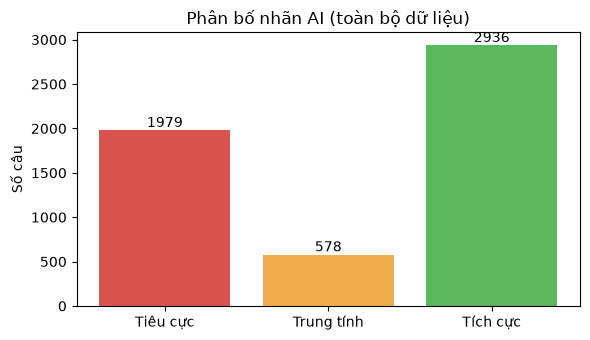

In [5]:
# Hình 3.1: Phân bố nhãn AI trên toàn bộ dữ liệu
MAU = ['#d9534f', '#f0ad4e', '#5cb85c']
dem = df_tong['label'].value_counts().reindex(LABELS)
plt.figure(figsize=(6, 3.5))
cot = plt.bar(NAMES, dem.values, color=MAU)
plt.bar_label(cot)
plt.title('Phân bố nhãn AI (toàn bộ dữ liệu)')
plt.ylabel('Số câu')
plt.tight_layout()
plt.savefig(OUT / 'hinh_3_1_phan_bo_nhan.png', dpi=200)
plt.show()

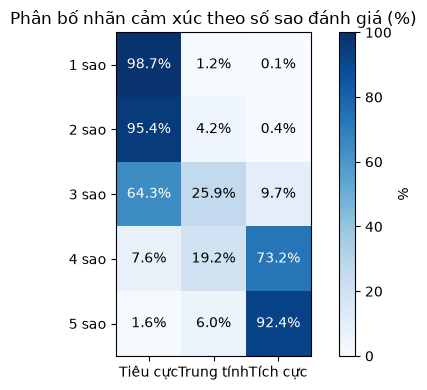

In [6]:
ti_le_sao = pd.crosstab(df_clean['so_sao'], df_tong['label'], normalize='index') * 100
plt.figure(figsize=(6, 4))
plt.imshow(ti_le_sao.values, cmap='Blues', vmin=0, vmax=100)
plt.xticks(range(3), NAMES)
plt.yticks(range(len(ti_le_sao)), [f"{s} sao" for s in ti_le_sao.index])
for (i, j), v in np.ndenumerate(ti_le_sao.values):
    plt.text(j, i, f"{v:.1f}%", ha='center', va='center', color='white' if v > 50 else 'black')
plt.title("Phân bố nhãn cảm xúc theo số sao đánh giá (%)")
plt.colorbar(label='%')
plt.tight_layout()
plt.show()

,count,mean,std,min,25%,50%,75%,max
Tiêu cực,1979.0,35.2,41.6,1.0,14.0,24.0,42.0,889.0
Trung tính,578.0,22.8,19.0,1.0,11.0,20.0,29.0,239.0
Tích cực,2936.0,15.3,15.7,1.0,5.0,11.0,21.0,238.0


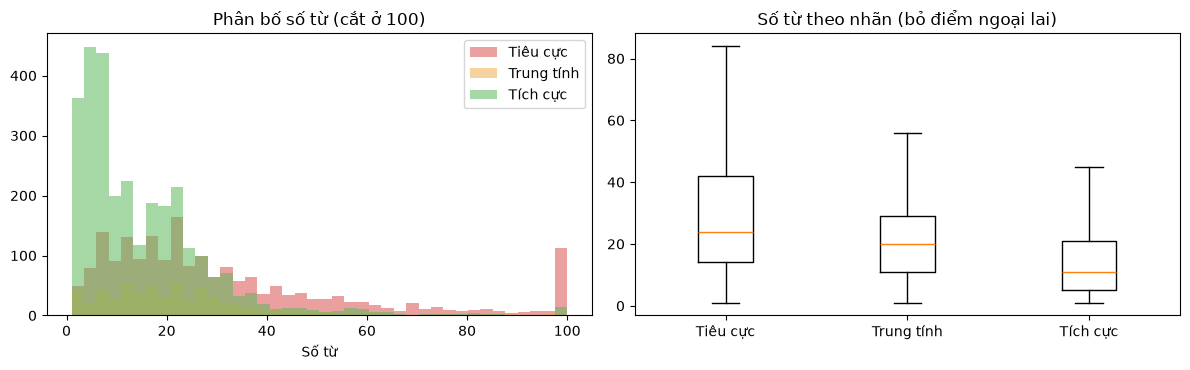

In [8]:
# Hình 3.2: Độ dài đánh giá (số từ) theo nhãn
so_tu = df_tong['noi_dung'].astype(str).str.split().str.len()
display(so_tu.groupby(df_tong['label']).describe().round(1).set_axis(NAMES))
so_tu_theo_nhan = [so_tu[df_tong['label'] == c] for c in LABELS]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for s, ten, mau in zip(so_tu_theo_nhan, NAMES, MAU):
    ax[0].hist(s.clip(upper=100), bins=40, alpha=0.55, label=ten, color=mau)
ax[0].set_title('Phân bố số từ (cắt ở 100)')
ax[0].set_xlabel('Số từ')
ax[0].legend()
ax[1].boxplot(so_tu_theo_nhan, showfliers=False)
ax[1].set_xticks([1, 2, 3], NAMES)
ax[1].set_title('Số từ theo nhãn (bỏ điểm ngoại lai)')
plt.tight_layout()
plt.savefig(OUT / 'hinh_3_2_do_dai.png', dpi=200)
plt.show()

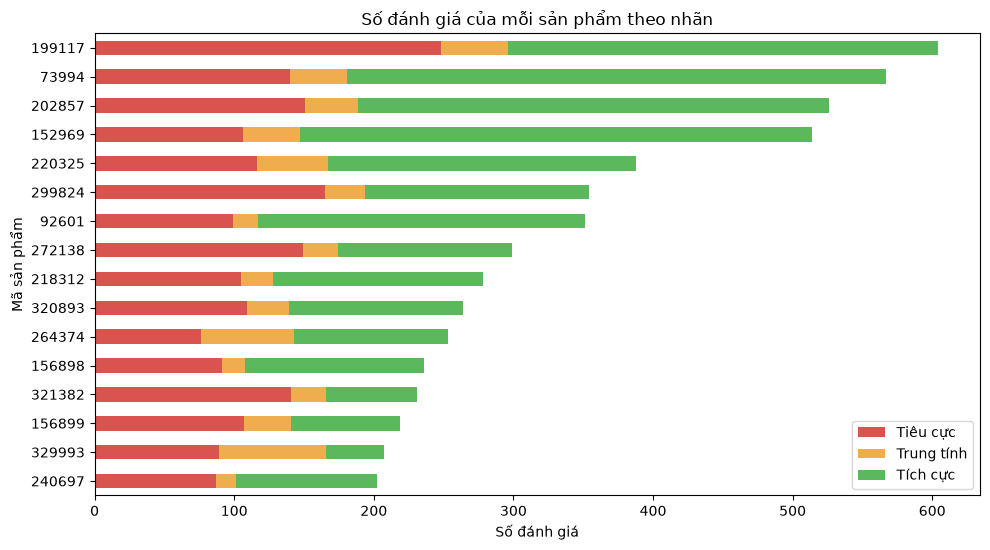

In [9]:
# Hình 3.3: Số đánh giá của mỗi sản phẩm theo nhãn
nhan_sp = df_tong[['review_id', 'label']].merge(df_clean[['review_id', 'product_id']], on='review_id')
sp = pd.crosstab(nhan_sp['product_id'], nhan_sp['label']).reindex(columns=LABELS)
sp.columns = NAMES
sp = sp.loc[sp.sum(axis=1).sort_values(ascending=False).index]

ax = sp.plot(kind='barh', stacked=True, figsize=(10, 5.6), color=MAU)
ax.invert_yaxis()
ax.set_xlabel('Số đánh giá')
ax.set_ylabel('Mã sản phẩm')
ax.set_title('Số đánh giá của mỗi sản phẩm theo nhãn')
plt.tight_layout()
plt.savefig(OUT / 'hinh_3_3_san_pham.png', dpi=200)
plt.show()

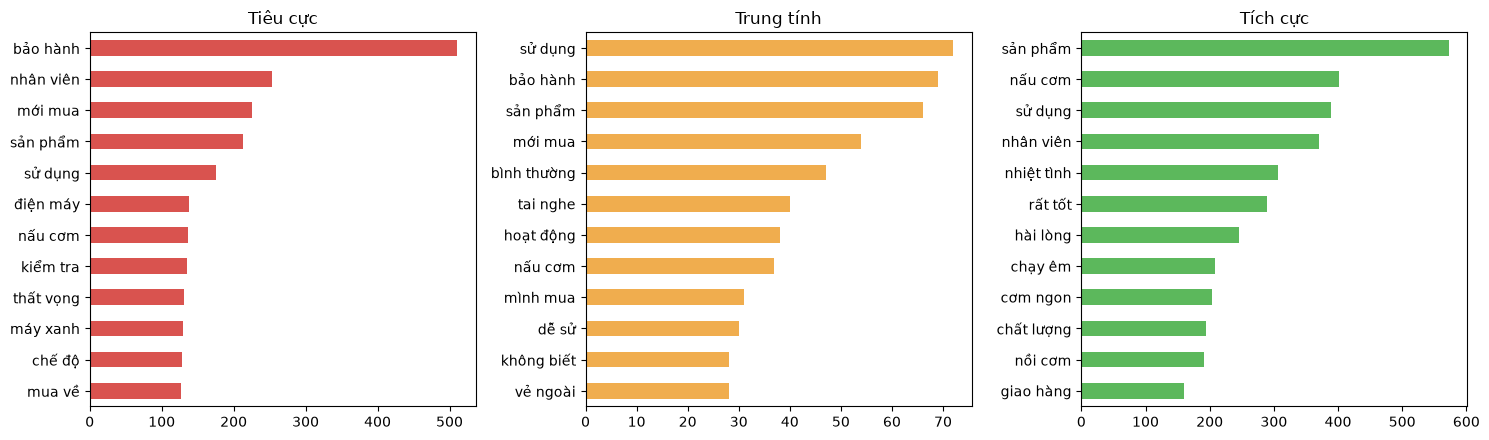

In [10]:
# Hình 3.4: Các cụm 2 âm tiết hay gặp nhất theo nhãn
def cum_pho_bien(cac_cau, n=12):
    dem = CountVectorizer(ngram_range=(2, 2), token_pattern=r'(?u)\b\w+\b')
    tong = np.asarray(dem.fit_transform(cac_cau.str.lower()).sum(axis=0)).ravel()
    top = np.argsort(-tong)[:n]
    return pd.Series(tong[top], index=dem.get_feature_names_out()[top])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, c, ten, mau in zip(axes, LABELS, NAMES, MAU):
    cum_pho_bien(df_tong.loc[df_tong['label'] == c, 'noi_dung'])[::-1].plot(kind='barh', ax=ax, color=mau)
    ax.set_title(ten)
plt.tight_layout()
plt.savefig(OUT / 'hinh_3_4_cum_tu.png', dpi=200)
plt.show()

## 2. Split (Phân chia tập dữ liệu)
- **Test**              : Sử dụng toàn bộ 500 câu do người gán tay (`df_per`).
- **Train & Validation**: Lấy từ tập toàn bộ (`df_tong`) sau khi loại bỏ 500 câu Test .
- Chia tỷ lệ 85% Train và 15% Validation, sử dụng `stratify` để bảo toàn tỷ lệ giữa các nhãn.


In [11]:
test = df_per[['review_id', 'noi_dung', 'label']].copy()
test['label'] = test['label'].astype(int)
# Ghép thêm cột 'so_sao' từ df_clean vào test
sao_dict = df_clean.set_index('review_id')['so_sao']
test['so_sao'] = test['review_id'].map(sao_dict)

id_da_test = set(test['review_id'])
tap_con_lai = df_tong[~df_tong['review_id'].isin(id_da_test)].copy()
tap_con_lai['label'] = tap_con_lai['label'].astype(int)
tap_con_lai['so_sao'] = tap_con_lai['review_id'].map(sao_dict)

# 3. Phân tách Train và Validation
train, val = train_test_split(
    tap_con_lai, 
    test_size=0.15, 
    random_state=SEED, 
    stratify=tap_con_lai['label']
)

# Bổ sung nhãn quy đổi từ số sao làm đối chứng baseline
nhan_sao_map = dict(zip([1, 2, 3, 4, 5], [-1, -1, 0, 1, 1]))
for d in (train,val,test):
    d['nhan_sao']=d['so_sao'].map(nhan_sao_map)

table = pd.DataFrame({
    'Train': train['label'].value_counts(),
    'Val': val['label'].value_counts(),
    'Test': test['label'].value_counts()
})
table.loc['Tổng'] = table.sum()
assert not set(train['review_id']) & set(test['review_id']), 'Train bị lẫn câu của test'
assert not set(val['review_id']) & set(test['review_id']), 'Val bị lẫn câu của test'
assert test['so_sao'].notna().all(), 'Có câu test không tìm được số sao'
table


,Train,Val,Test
label,,,
1,2280,402,252
-1,1528,270,176
0,436,77,72
Tổng,4244,749,500


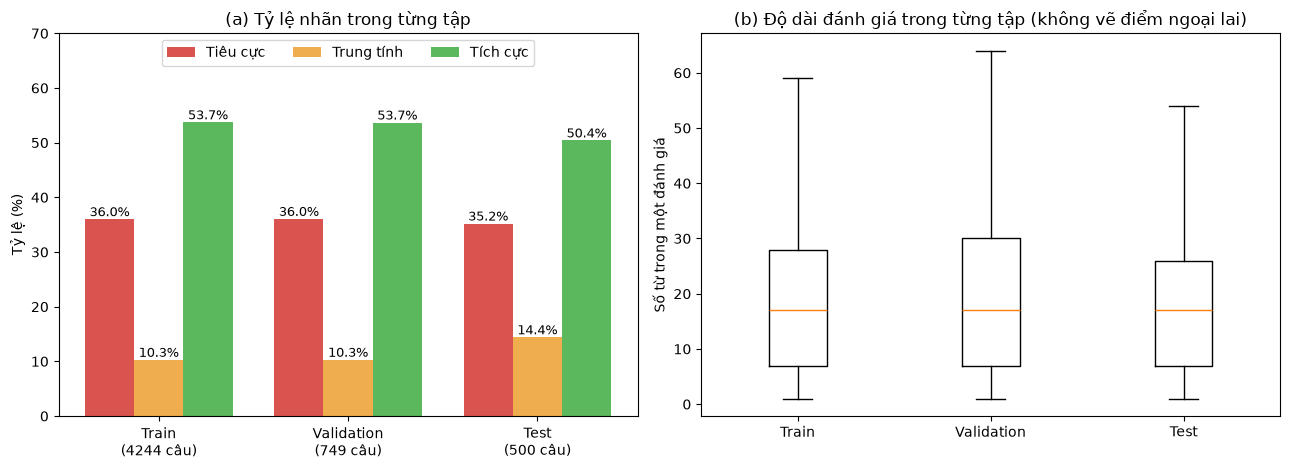

In [12]:
# Hình 3.5: Tỷ lệ nhãn và độ dài đánh giá trong từng tập
cac_tap = {'Train': train, 'Validation': val, 'Test': test}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
vi_tri = np.arange(3)
for k, (c, ten, mau) in enumerate(zip(LABELS, NAMES, MAU)):
    ti_le = [(d['label'] == c).mean() * 100 for d in cac_tap.values()]
    cot = ax[0].bar(vi_tri + (k - 1) * 0.26, ti_le, 0.26, color=mau, label=ten)
    ax[0].bar_label(cot, fmt='%.1f%%', fontsize=9)
ax[0].set_xticks(vi_tri, [f'{ten}\n({len(d)} câu)' for ten, d in cac_tap.items()])
ax[0].set_ylim(0, 70)
ax[0].set_ylabel('Tỷ lệ (%)')
ax[0].set_title('(a) Tỷ lệ nhãn trong từng tập')
ax[0].legend(ncol=3, loc='upper center')

do_dai = [d['noi_dung'].str.split().str.len() for d in cac_tap.values()]
ax[1].boxplot(do_dai, showfliers=False)
ax[1].set_xticks([1, 2, 3], list(cac_tap))
ax[1].set_ylabel('Số từ trong một đánh giá')
ax[1].set_title('(b) Độ dài đánh giá trong từng tập (không vẽ điểm ngoại lai)')
plt.tight_layout()
plt.savefig(OUT / 'hinh_3_5_chia_tap.png', dpi=200)
plt.show()

## 3. Preprocessed (Xử lý sâu văn bản)
1. Chuyển chữ thường và chuẩn hóa Unicode (NFC).
2. Tra cứu và thay thế các từ viết tắt qua từ điển `teencode.csv`.
3. Phân tách từ vựng tiếng Việt bằng `underthesea`.
4. Lọc bỏ các từ dừng từ kho `tu_dung.txt` đã tinh chỉnh.
5. Loại bỏ triệt để các token chỉ toàn chữ số (ngày tháng, số rác: '2024', '18 05', '000').


In [13]:
bang_teencode = pd.read_csv(data / "teencode.csv", dtype=str, keep_default_na=False)
tu_dien_teencode = dict(zip(bang_teencode['viet_tat'].str.strip(), bang_teencode['day_du'].str.strip()))

with open(data / "tu_dung.txt", encoding="utf-8") as f:
    kho_tu_dung = set(line.strip() for line in f if line.strip())

def xu_ly_cau(van_ban):
    cau = unicodedata.normalize("NFC", str(van_ban)).lower()
    tokens = []
    for doan in re.split(r'[^\w\s]+', cau):          # cắt theo dấu câu trước khi tách từ
        tu = [tu_dien_teencode.get(w, w) for w in doan.split()]
        if not tu:
            continue
        for w in word_tokenize(" ".join(tu)):
            w = w.replace(' ', '_')
            if w not in kho_tu_dung and re.search(r'[^\W\d_]', w):  # có ít nhất 1 chữ cái
                tokens.append(w)
    return " ".join(tokens)

for d in (train, val, test):
    d['van_ban'] = d['noi_dung'].apply(xu_ly_cau)

print(f'Kho từ dừng: {len(kho_tu_dung):,} từ')
display(train[['noi_dung', 'van_ban', 'label']].head(5))

train.info()


Kho từ dừng: 39 từ


,noi_dung,van_ban,label
220,"Sản phẩm bình thường, độ làm mát kém ngay cả khi đã nạp bình đá khô😑",sản_phẩm bình_thường độ làm mát_kém ngay cả khi đã nạp bình đá khô,-1
854,"Sản phẩm ổn, hình thức đẹp, nấu cơm cũng ngon, nhanh chín, nấu ít gạo cũng vẫn ngon cơm",sản_phẩm ổn hình_thức đẹp nấu cơm cũng ngon nhanh chín nấu ít gạo cũng vẫn ngon cơm,1
4889,"Nấu cơm ngon, giữ nhiệt tốt",nấu cơm ngon giữ nhiệt tốt,1
3138,Ok tạm thời thấy tốt cơm chín đều,ok tạm_thời thấy tốt cơm chín đều,1
3166,"Mình đã mua và sử dụng được 1 năm, chưa thấy hỏng hóc gì, nói chung với giá tiền lúc mình mua dưới 300k thì thấy chấ...",đã mua sử_dụng được năm chưa thấy hỏng hóc gì nói_chung giá tiền lúc mua k thì thấy chất_lượng khá ổn nồi nấu cơm dễ...,1


<class 'pandas.DataFrame'>
Index: 4244 entries, 220 to 2590
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review_id  4244 non-null   int64
 1   noi_dung   4244 non-null   str  
 2   label      4244 non-null   int64
 3   so_sao     4244 non-null   int64
 4   nhan_sao   4244 non-null   int64
 5   van_ban    4244 non-null   str  
dtypes: int64(4), str(2)
memory usage: 232.1 KB


## 4. Feature extraction (Trích chọn đặc trưng)
1. **BoW**: đếm unigram và bigram, bỏ từ chỉ xuất hiện 1 lần (`min_df=2`)
2. **TF-IDF**: như BoW nhưng hạ trọng số những từ câu nào cũng có, dùng $1+\log(tf)$
3. **Word2Vec**: vector ngữ nghĩa dày 100 chiều. Vector câu là trung bình vector các từ trong câu


### Mô hình Bag-of-Words (BoW)


In [14]:
vec_bow = CountVectorizer(ngram_range=(1, 2), min_df=2)
X_train_bow = vec_bow.fit_transform(train['van_ban'])
X_val_bow = vec_bow.transform(val['van_ban'])
X_test_bow = vec_bow.transform(test['van_ban'])
print('BoW Size:', X_train_bow.shape[1])

BoW Size: 10354


In [15]:
# Khảo sát danh sách đặc trưng BoW
feature_names = vec_bow.get_feature_names_out()
print('100 đặc trưng đầu:')
print(feature_names[:100])
print('100 đặc trưng cuối:')
print(feature_names[-100:])

100 đặc trưng đầu:
['ace' 'ad' 'ae' 'ae không' 'ah' 'ai' 'ai chịu' 'ai có' 'ai cũng' 'ai dám'
 'ai dè' 'ai giải_quyết' 'ai gọi' 'ai hỗ_trợ' 'ai liên_hệ' 'ai mua'
 'ai muốn' 'ai mà' 'ai nghe' 'ai thích' 'ai đến' 'ai_ngờ' 'ak' 'an'
 'an_toàn' 'an_tâm' 'anh_chị' 'anh_em' 'ap' 'app' 'app quà' 'auto' 'ava'
 'ba' 'ba_mẹ' 'ban' 'ban_ngày' 'ban_đêm' 'ban_đêm mở' 'ban_đêm ngủ'
 'ban_đầu' 'ban_đầu mua' 'bao' 'bao_giờ' 'bao_giờ bị' 'bao_giờ mua'
 'bao_giờ phải' 'bao_giờ thấy' 'bao_gồm' 'bao_hành' 'bao_hành như'
 'bao_lâu' 'bao_lâu thì' 'bao_nhiêu' 'bass' 'bat' 'bay' 'ben' 'bhx' 'bi'
 'bin' 'binh' 'biét' 'biêt' 'biến_dạng' 'biết' 'biết ai' 'biết bảo_hành'
 'biết bị' 'biết bộ_phận' 'biết chất_lượng' 'biết chứ' 'biết cách'
 'biết còn' 'biết có' 'biết có_thể' 'biết do' 'biết dùng' 'biết gì'
 'biết hiện_tại' 'biết khi' 'biết làm' 'biết lỗi' 'biết máy'
 'biết nguyên_nhân' 'biết như_thế_nào' 'biết nhưng' 'biết nói' 'biết nước'
 'biết nấu' 'biết nữa' 'biết phải' 'biết ra' 'biết sao' 'biết sau'
 'biết sài

In [16]:
# Trích xuất mẫu vector BoW của 1 bình luận
print('Raw:', train.iloc[36]['noi_dung'])
print('Processed:', train.iloc[36]['van_ban'])
print('Vector BoW:', X_train_bow[36].toarray())
np.savetxt('out/vector_bow.txt', X_train_bow[36].toarray().ravel(), fmt='%.6f')
print('Shape:', X_train_bow[36].shape)

Raw: Máy sử dụng tốt, nhân viên thái độ nhiệt tình, chu đáo, rất hài lòng.
Processed: máy sử_dụng tốt nhân_viên thái_độ nhiệt_tình chu_đáo rất hài_lòng
Vector BoW: [[0 0 0 ... 0 0 0]]
Shape: (1, 10354)


### Mô hình TF-IDF (Term Frequency - Inverse Document Frequency)


In [17]:
vec_tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_tfidf = vec_tfidf.fit_transform(train['van_ban'])
X_val_tfidf = vec_tfidf.transform(val['van_ban'])
X_test_tfidf = vec_tfidf.transform(test['van_ban'])
print('TF-IDF Size:', X_train_tfidf.shape[1])

TF-IDF Size: 10354


In [18]:
# Trích xuất mẫu vector TF-IDF của 1 bình luận
print('Raw:', train.iloc[36]['noi_dung'])
print('Processed:', train.iloc[36]['van_ban'])
print('Vector TF-IDF:', X_train_tfidf[36].toarray())
np.savetxt('out/vector_tfidf.txt', X_train_tfidf[36].toarray().ravel(), fmt='%.6f')
print('Shape:', X_train_tfidf[36].shape)

Raw: Máy sử dụng tốt, nhân viên thái độ nhiệt tình, chu đáo, rất hài lòng.
Processed: máy sử_dụng tốt nhân_viên thái_độ nhiệt_tình chu_đáo rất hài_lòng
Vector TF-IDF: [[0. 0. 0. ... 0. 0. 0.]]
Shape: (1, 10354)


### Mô hình Word2Vec (Average)
- Huấn luyện vector ngữ nghĩa 100 chiều từ tập Train.
- Mỗi bình luận được biểu diễn bằng vector trung bình cộng (Average Pooling) của các từ có trong câu.


In [19]:
sentences = []                      
for s in train['van_ban']:          
    cac_tu = s.split()              
    sentences.append(cac_tu)      
w2v_model = Word2Vec(sentences, vector_size=100, window=5, min_count=2,
                     sg=1, negative=5, epochs=30, workers=1, seed=SEED)
print('Word2Vec Size:', len(w2v_model.wv))

Word2Vec Size: 2296


In [20]:
# Khảo sát từ vựng đã học trong mô hình Word2Vec
print('100 từ đầu:')
print(w2v_model.wv.index_to_key[:100])
print('100 từ cuối:')
print(w2v_model.wv.index_to_key[-100:])

100 từ đầu:
['không', 'mua', 'rất', 'được', 'thì', 'cơm', 'tốt', 'có', 'nồi', 'nấu', 'máy', 'mới', 'sản_phẩm', 'bị', 'dùng', 'mà', 'nhân_viên', 'nhưng', 'ok', 'bảo_hành', 'sử_dụng', 'hàng', 'cũng', 'ngày', 'về', 'nên', 'quạt', 'đã', 'lại', 'ngon', 'nhanh', 'làm', 'chạy', 'thấy', 'điện', 'chưa', 'quá', 'nước', 'tháng', 'rồi', 'mát', 'lần', 'đẹp', 'khi', 'êm', 'đổi', 'lạnh', 'như', 'kêu', 'tủ', 'xài', 'giá', 'phải', 'người', 'ra', 'bên', 'vẫn', 'đến', 'hơn', 'còn', 'lỗi', 'hết', 'gì', 'nhiệt_tình', 'nhiều', 'chín', 'lúc', 'biết', 'tệ', 'giao', 'hài_lòng', 'nữa', 'sao', 'ổn', 'đmx', 'sau', 'khác', 'gọi', 'hãng', 'giờ', 'nóng', 'chất_lượng', 'tiền', 'hơi', 'nghe', 'ồn', 'tiếng', 'luôn', 'lên', 'lắm', 'xanh', 'ạ', 'hư', 'mọi', 'vậy', 'chỉ', 'sạc', 'khá', 'sẽ', 'vào']
100 từ cuối:
['khọt', 'đối_phương', 'ghi_âm', 'giật_điện', 'cồng_kềnh', 'hoàn_pmh', 'giở', 'phê', 'đòi_hỏi', 'tồi', 'trần', 'tầng', 'va_chạm', 'sém', 'sỏn', 'lát', 'tự_bật', 'chào', 'rũ', 'kêt', 'bèo', 'nầy', 'chiecs', 'xửng_hấ

In [21]:
# Các từ gần nghĩa nhất theo Word2Vec (dùng ở mục 3.3)
for tu in ['tốt', 'tệ', 'bảo_hành']:
    gan = [(w, round(s, 2)) for w, s in w2v_model.wv.most_similar(tu, topn=6)]
    print(tu, '→', gan)

tốt → [('ok', 0.68), ('ổn_áp', 0.66), ('mẫu_mã', 0.63), ('tk', 0.63), ('hợp_lí', 0.63), ('hihi', 0.63)]
tệ → [('kém', 0.59), ('thực_sự', 0.57), ('đỗ', 0.52), ('dạo', 0.52), ('lắp_ráp', 0.51), ('bèo', 0.51)]
bảo_hành → [('thời_hạn', 0.59), ('b', 0.58), ('chậm_chạp', 0.58), ('hà_nội', 0.56), ('hạn', 0.56), ('rôi', 0.56)]


In [22]:
# Minh họa vector embedding của 1 từ cụ thể
word = w2v_model.wv.index_to_key[36]
print('Từ:', word)
print('Vector:', w2v_model.wv[word])
print('Shape:', w2v_model.wv[word].shape)

Từ: quá
Vector: [ 8.0368802e-02  2.4045452e-02 -2.5962076e-01 -1.0524656e-01
  1.6974580e-01  2.4430604e-01 -3.2908627e-01  2.7254924e-01
  1.6147897e-01  5.3280205e-02 -3.0225024e-01  3.1318510e-01
  2.3055403e-01 -4.5225721e-02  2.8947499e-01 -5.2801651e-01
 -4.3490446e-01 -3.8300830e-01 -3.6153275e-01 -9.8278046e-02
  3.5459301e-01  2.8879336e-01  6.8816549e-01  3.4577277e-01
  5.4195827e-01  1.5275504e-01  4.5015510e-02 -1.0680179e-02
  3.9028692e-01 -1.6984203e-01 -2.5617883e-01 -4.7182411e-02
 -4.7768670e-01 -9.8768122e-02  5.7308745e-01  2.5159505e-01
 -3.9865688e-04 -5.4150742e-01 -3.6842474e-01  3.0374512e-01
  2.7992788e-01  2.5451374e-01  3.5568985e-01 -6.6788149e-01
 -2.0711125e-01  4.3645754e-01 -5.8034211e-02  2.9933932e-01
  4.9656630e-01  1.2957737e-01 -6.1159861e-01 -6.1694634e-01
 -1.0344964e-01  9.4631582e-02  1.8305883e-01  1.0029588e-01
  8.2781583e-02  4.2822722e-01 -5.1263771e-03 -3.5866755e-01
 -3.1232783e-01  2.1588719e-01  5.0933141e-01  7.7750045e-01
  1.6625

In [ ]:
# Biểu diễn bình luận bằng trung bình cộng vector từ (Word2Vec Average Pooling)
def doc_vector_avg(tokens):
    vecs = []
    for w in tokens:
        if w in w2v_model.wv:
            vecs.append(w2v_model.wv[w])
    if len(vecs) > 0:
        vector_cau = np.mean(vecs, axis=0)     
        return vector_cau
    else:
        return np.zeros(w2v_model.wv.vector_size) 

def bien_doi_tap_van_ban(cac_cau):
    danh_sach_vector = []
    for s in cac_cau:
        cac_tu = s.split()
        vector_cau = doc_vector_avg(cac_tu)
        danh_sach_vector.append(vector_cau)
    return np.array(danh_sach_vector)

X_train_w2v_avg = bien_doi_tap_van_ban(train['van_ban'])
X_val_w2v_avg   = bien_doi_tap_van_ban(val['van_ban'])
X_test_w2v_avg  = bien_doi_tap_van_ban(test['van_ban'])

In [24]:
# Trích xuất mẫu vector Word2Vec Average
print('Processed:', train.iloc[36]['van_ban'])
print('Vector Word2Vec Avg:', X_train_w2v_avg[36])
print('Shape:', X_train_w2v_avg[36].shape)
np.savetxt('out/vector_w2v_avg.txt', X_train_w2v_avg[36], fmt='%.6f')

Processed: máy sử_dụng tốt nhân_viên thái_độ nhiệt_tình chu_đáo rất hài_lòng
Vector Word2Vec Avg: [ 7.89083786e-01  3.32362593e-01  1.31936239e+00  9.38204488e-02
 -1.12743111e+00 -5.62636573e-01 -3.41912342e-01  3.20926834e-01
 -1.00165535e+00  5.35982251e-01 -4.86154570e-01  2.70125954e-01
  2.04076200e-01  3.11950417e-01 -8.69356857e-01 -1.41868616e+00
 -5.60610869e-01 -6.48236004e-01 -1.41915671e+00  7.18133488e-02
  6.53683873e-01  7.07303870e-01 -3.65545928e-01  9.06359239e-01
  1.65075155e+00  3.67323204e-01 -1.47794100e+00  2.06797167e+00
 -2.35835350e-01  1.17607719e-01 -1.26527148e+00  2.02681844e+00
 -1.49522233e+00 -1.26142296e+00 -1.12746781e+00  3.34279976e-01
  3.52667437e-02 -1.71619370e+00  9.32343917e-01  6.41225936e-01
 -1.33354845e+00  6.27788399e-01 -3.25704477e-02  1.12833015e+00
 -9.58773510e-01 -4.32185596e-01 -8.56340918e-01  1.83920462e+00
  1.42896623e+00  1.06847322e+00 -1.21104043e-01 -1.68437857e+00
 -3.19883909e-01  4.78497982e-01  5.31527305e-01  4.10957

## 5. Huấn luyện mô hình
Huấn luyện 2 thuật toán học máy (**Naive Bayes** và **SVM**) trên các phương pháp trích chọn đặc trưng:
- **Naive Bayes (MultinomialNB)**: Huấn luyện trên **BoW** và **TF-IDF** (thích hợp với vector tần số đếm và trọng số không âm $\ge 0$). Điều chỉnh siêu tham số làm mịn lpha theo tập validation.
- **SVM (LinearSVC)**: Huấn luyện trên cả 3 đặc trưng (**BoW**, **TF-IDF**, **Word2Vec**), đặt class_weight='balanced'.Điều chỉnh siêu tham số phạt C theo tập validation.


In [25]:
y_train = train['label']
y_val = val['label']

X_train = {
    'BoW': X_train_bow,
    'TF-IDF': X_train_tfidf,
    'Word2Vec': X_train_w2v_avg
}
X_val = {
    'BoW': X_val_bow,
    'TF-IDF': X_val_tfidf,
    'Word2Vec': X_val_w2v_avg
}

# Điều chỉnh siêu tham số alpha cho Naive Bayes theo tập val
best_nb = {}
for feat in ['BoW', 'TF-IDF']:
    best_score, best_model, best_alpha = -1, None, None
    for a in [0.01, 0.1, 0.5, 1.0, 2.0]:
        m = MultinomialNB(alpha=a).fit(X_train[feat], y_train)
        score = f1_score(y_val, m.predict(X_val[feat]), average='macro')
        if score > best_score:
            best_score, best_model, best_alpha = score, m, a
    best_nb[feat] = best_model
    print(f'Đã chọn Naive Bayes ({feat}) tốt nhất: alpha={best_alpha} (Macro F1: {best_score:.4f})')

# Điều chỉnh siêu tham số C cho SVM theo tập val
best_svm = {}
for feat in ['BoW', 'TF-IDF', 'Word2Vec']:
    best_score, best_model, best_c = -1, None, None
    for c in [0.01, 0.1, 0.5, 1.0, 2.0]:
        m = LinearSVC(C=c, class_weight='balanced', max_iter=5000, random_state=42).fit(X_train[feat], y_train)
        score = f1_score(y_val, m.predict(X_val[feat]), average='macro')
        if score > best_score:
            best_score, best_model, best_c = score, m, c
    best_svm[feat] = best_model
    print(f'Đã chọn SVM ({feat}) tốt nhất: C={best_c} (Macro F1: {best_score:.4f})')

# Đóng gói 5 mô hình tối ưu đã huấn luyện cho phần đánh giá
trained_models = {
    ('BoW', 'Naive Bayes'): best_nb['BoW'],
    ('TF-IDF', 'Naive Bayes'): best_nb['TF-IDF'],
    ('BoW', 'SVM'): best_svm['BoW'],
    ('TF-IDF', 'SVM'): best_svm['TF-IDF'],
    ('Word2Vec', 'SVM'): best_svm['Word2Vec'],
}

print(f'Đã huấn luyện hoàn tất {len(trained_models)} mô hình')

Đã chọn Naive Bayes (BoW) tốt nhất: alpha=0.1 (Macro F1: 0.7436)
Đã chọn Naive Bayes (TF-IDF) tốt nhất: alpha=0.01 (Macro F1: 0.6921)
Đã chọn SVM (BoW) tốt nhất: C=0.1 (Macro F1: 0.7640)
Đã chọn SVM (TF-IDF) tốt nhất: C=2.0 (Macro F1: 0.7873)
Đã chọn SVM (Word2Vec) tốt nhất: C=0.01 (Macro F1: 0.7324)
Đã huấn luyện hoàn tất 5 mô hình


## 6. Đánh giá
Các cột từ `Accuracy` trở đi là điểm trên **test**. Bảng được sắp xếp theo Macro F1 trên validation.

In [26]:
# Đóng gói dữ liệu đánh giá và chạy dự đoán từ các mô hình đã huấn luyện ở Mục 6
y = {'val': val['label'], 'test': test['label']}
X = {
    'BoW': {'val': X_val_bow, 'test': X_test_bow},
    'TF-IDF': {'val': X_val_tfidf, 'test': X_test_tfidf},
    'Word2Vec': {'val': X_val_w2v_avg, 'test': X_test_w2v_avg}
}

def tinh_diem(y_true, y_pred):
    f1_tung_lop = f1_score(y_true, y_pred, average=None, labels=LABELS)
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Macro F1': f1_score(y_true, y_pred, average='macro'),
        **{f'F1 {ten}': f for ten, f in zip(NAMES, f1_tung_lop)}
    }

def ghi_ket_qua(feature, model, p_val, p_test):
    results.append({
        'Feature': feature,
        'Model': model,
        'Val Macro F1': f1_score(y['val'], p_val, average='macro'),
        **tinh_diem(y['test'], p_test)
    })

results, predictions = [], {}

# Baseline đối chứng
lop_nhieu = train['label'].mode()[0]
ghi_ket_qua('(baseline)', 'Luôn đoán lớp nhiều nhất', np.full(len(val), lop_nhieu), np.full(len(test), lop_nhieu))
ghi_ket_qua('(baseline)', 'Nhãn theo số sao', val['nhan_sao'], test['nhan_sao'])

# Dự đoán và ghi nhận kết quả đánh giá cho 6 mô hình đã huấn luyện
for (feat, algo), model in trained_models.items():
    predictions[(feat, algo)] = model.predict(X[feat]['test'])
    p_val = model.predict(X[feat]['val'])
    ghi_ket_qua(feat, algo, p_val, predictions[(feat, algo)])

scores = pd.DataFrame(results).sort_values('Val Macro F1', ascending=False).round(4).reset_index(drop=True)
scores


,Feature,Model,Val Macro F1,Accuracy,Macro F1,F1 Tiêu cực,F1 Trung tính,F1 Tích cực
0,TF-IDF,SVM,0.7873,0.856,0.7629,0.8696,0.4874,0.9318
1,BoW,SVM,0.7640,0.860,0.7732,0.8715,0.5120,0.9362
2,BoW,Naive Bayes,0.7436,0.836,0.7415,0.8415,0.4628,0.9201
3,Word2Vec,SVM,0.7324,0.836,0.7490,0.8368,0.4957,0.9145
4,TF-IDF,Naive Bayes,0.6921,0.816,0.6880,0.8175,0.3366,0.9098
5,(baseline),Nhãn theo số sao,0.6892,0.768,0.6487,0.8013,0.2639,0.8809
6,(baseline),Luôn đoán lớp nhiều nhất,0.2328,0.504,0.2234,0.0000,0.0000,0.6702


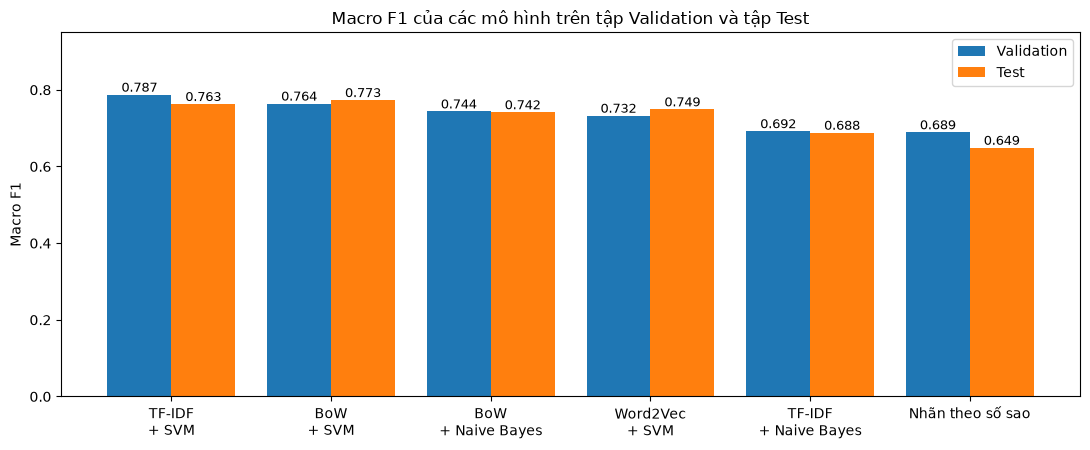

In [27]:
# Hình 3.6: Macro F1 trên tập Validation và tập Test (bỏ baseline luôn đoán 1 lớp)
ve = scores[scores['Model'] != 'Luôn đoán lớp nhiều nhất'].copy()
ve['ten'] = np.where(ve['Feature'] == '(baseline)', ve['Model'], ve['Feature'] + '\n+ ' + ve['Model'])
vi_tri = np.arange(len(ve))

plt.figure(figsize=(11, 4.6))
c1 = plt.bar(vi_tri - 0.2, ve['Val Macro F1'], 0.4, label='Validation')
c2 = plt.bar(vi_tri + 0.2, ve['Macro F1'], 0.4, label='Test')
plt.bar_label(c1, fmt='%.3f', fontsize=9)
plt.bar_label(c2, fmt='%.3f', fontsize=9)
plt.xticks(vi_tri, ve['ten'])
plt.ylim(0, 0.95)
plt.ylabel('Macro F1')
plt.title('Macro F1 của các mô hình trên tập Validation và tập Test')
plt.legend()
plt.tight_layout()
plt.savefig(OUT / 'hinh_3_6_macro_f1.png', dpi=200)
plt.show()

### Mô hình tốt nhất (chọn theo validation): ma trận nhầm lẫn và báo cáo trên test

Mô hình chọn: TF-IDF + SVM


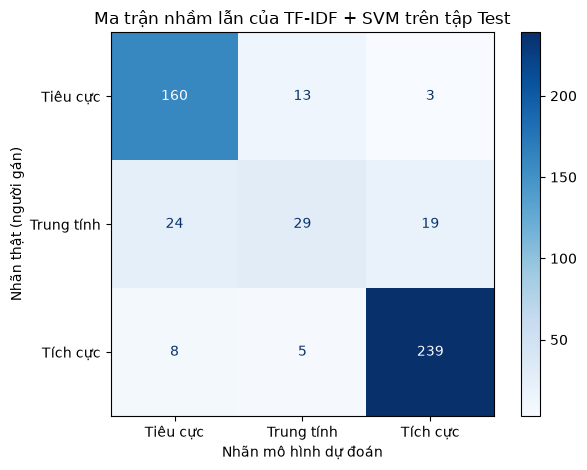

              precision    recall  f1-score   support

    Tiêu cực     0.8333    0.9091    0.8696       176
  Trung tính     0.6170    0.4028    0.4874        72
    Tích cực     0.9157    0.9484    0.9318       252

    accuracy                         0.8560       500
   macro avg     0.7887    0.7534    0.7629       500
weighted avg     0.8437    0.8560    0.8459       500



In [28]:
best = tuple(scores.loc[scores['Feature'] != '(baseline)'].iloc[0][['Feature', 'Model']])
print('Mô hình chọn:', ' + '.join(best))

# Hình 3.7: Ma trận nhầm lẫn của mô hình tốt nhất trên tập test
cm = confusion_matrix(y['test'], predictions[best], labels=LABELS)
ConfusionMatrixDisplay(cm, display_labels=NAMES).plot(cmap='Blues')
plt.xlabel('Nhãn mô hình dự đoán')
plt.ylabel('Nhãn thật (người gán)')
plt.title('Ma trận nhầm lẫn của ' + ' + '.join(best) + ' trên tập Test')
plt.tight_layout()
plt.savefig(OUT / 'hinh_3_7_ma_tran_nham_lan.png', dpi=200)
plt.show()

# Bảng 3.9: Precision, Recall, F1 từng lớp
print(classification_report(y['test'], predictions[best], labels=LABELS, target_names=NAMES, digits=4, zero_division=0))

In [29]:
# Các đặc trưng có trọng số lớn nhất của từng lớp trong mô hình tốt nhất (dùng ở mục 3.5.2)
if best[1] == 'SVM' and best[0] in ('BoW', 'TF-IDF'):
    ten_dac_trung = {'BoW': vec_bow, 'TF-IDF': vec_tfidf}[best[0]].get_feature_names_out()
    he_so = trained_models[best].coef_
    for i, ten in enumerate(NAMES):
        print(f'{ten}:', ', '.join(ten_dac_trung[np.argsort(-he_so[i])[:12]]))

Tiêu cực: tệ, không tốt, không mát, mà, không ok, không nên, hết, yếu, không ngon, khó_chịu, không hài_lòng, kêu
Trung tính: nhưng, tuy_nhiên, ngon nhưng, hỏi, bình_thường, chưa lắp, nhưng_mà, mỗi tội, tội, sao không, hình_ảnh, cũng bình_thường
Tích cực: tốt, ok, không bị, ngon, ổn, nhiệt_tình, nhanh, êm, tuyệt_vời, hài_lòng, đẹp, tot


### Phân tích lỗi

In [30]:
cols_hien_thi = [c for c in ['noi_dung', 'so_sao', 'label'] if c in test.columns]
sai = test[cols_hien_thi].assign(du_doan=predictions[best]).query('label != du_doan')
print(f'{len(sai)}/{len(test)} câu đoán sai')
sai.head(12)


72/500 câu đoán sai


,noi_dung,so_sao,label,du_doan
15,"Mới mua chưa được nổi 2 tháng đã hỏng, không biết có được bảo hành không, quá chán",1,-1,0
21,"Nồi bị rò điện ra vỏ, đem đổi cái khác cũng vậy. Không biết số mình xui mua trúng hàng lỗi hay mẫu này cái nào cũng ...",2,-1,0
26,Mua ngày 23/05Dùng 2 ngày sao kêu re re suốt ngày vậy,2,-1,0
28,Máy lúc mới lắp thì chạy OK sau hơn 1 tháng sử dụng thì máy làm mát rất yếu gọi nhân viên xuống kiểm tra thì lại báo...,1,0,-1
36,Nồi bị rò điện rất nguy hiểm Nhân viên nhiệt tình được đổi sp khác,1,0,-1
46,Đã sử dụng Hơi nhỏ Nhưng siêu thị ko cho đổi hàng,2,-1,0
56,"Quát xài mát thiệt, nhưng chưa hết thời gian bảo hảnh đã hư mạch vả rỉ nước",2,0,-1
78,có đổi dc không vậy đắt hơn nồi thường mà phải ăn cơm sống 2 ngày rồi,1,-1,0
97,Cực kỳ tệ,1,-1,0
99,Hút chưa sạch,2,-1,0


In [31]:
# Bảng 3.11: Đếm số câu đoán sai theo nhãn thật và nhãn dự đoán
ten_nhan = dict(zip(LABELS, NAMES))
loai_loi = sai.groupby(['label', 'du_doan']).size().reset_index(name='Số câu')
loai_loi['Nhãn thật'] = loai_loi['label'].map(ten_nhan)
loai_loi['Mô hình đoán'] = loai_loi['du_doan'].map(ten_nhan)
display(loai_loi.sort_values('Số câu', ascending=False)[['Nhãn thật', 'Mô hình đoán', 'Số câu']])

,Nhãn thật,Mô hình đoán,Số câu
2,Trung tính,Tiêu cực,24
3,Trung tính,Tích cực,19
0,Tiêu cực,Trung tính,13
4,Tích cực,Tiêu cực,8
5,Tích cực,Trung tính,5
1,Tiêu cực,Tích cực,3


In [32]:
scores.to_csv(OUT / 'model_scores.csv', index=False, encoding='utf-8-sig')
print('Đã lưu out/model_scores.csv')

Đã lưu out/model_scores.csv
